In [ ]:
cd /home/lihaoxing/jupyter

原始数据: 42 细胞, 20289 基因
过滤后: 42 细胞, 19376 基因
高变基因数量: 500


/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:72: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  warnings.warn(
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/scanpy/preprocessing/_pca.py:314: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm["X_pca"] = X_pca


聚类簇数: 2
警告：无分支节点，跳过细胞状态计算。


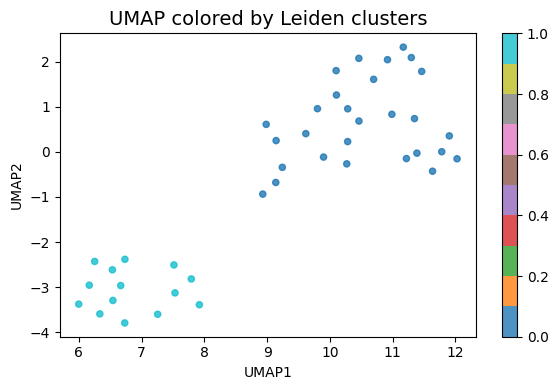

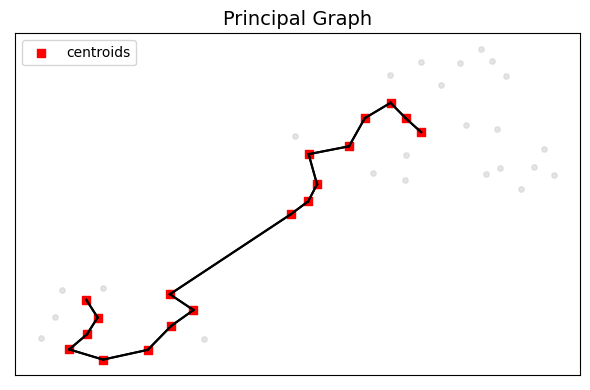

跳过 Cell States 图（无分支）。


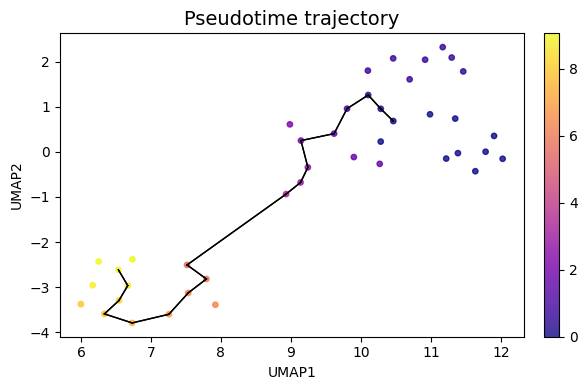

In [14]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
from scipy.sparse import csr_matrix
from py_monocle import learn_graph, order_cells, compute_cell_states
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ==================== 1. 读取表达量矩阵 ====================
df = pd.read_csv('IVF_2C_readcounts.txt', sep='\t', index_col=0)
adata = ad.AnnData(df.T)
print(f"原始数据: {adata.n_obs} 细胞, {adata.n_vars} 基因")

# ==================== 2. 预处理（针对小样本优化） ====================
# 小样本下放宽过滤条件：每个细胞至少表达 100 个基因（或总基因数的10%）
min_genes = max(100, int(0.1 * adata.n_vars))  # 动态调整
sc.pp.filter_cells(adata, min_genes=min_genes)
# 每个基因至少在 2 个细胞中表达（小样本下放宽）
sc.pp.filter_genes(adata, min_cells=2)

print(f"过滤后: {adata.n_obs} 细胞, {adata.n_vars} 基因")

# 标准化
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# 高变基因：小样本下 n_top_genes 不宜超过总基因数，取 500 或总基因数的 30%
n_top = min(500, int(0.3 * adata.n_vars))
sc.pp.highly_variable_genes(adata, n_top_genes=n_top, flavor='seurat_v3')
adata.raw = adata
adata = adata[:, adata.var.highly_variable]
print(f"高变基因数量: {adata.n_vars}")

# ==================== 3. 降维（PCA + UMAP）优化 ====================
# PCA 最大成分数不超过细胞数-1 且不超过 15
max_pcs = min(adata.n_obs - 1, 15)
sc.tl.pca(adata, n_comps=max_pcs, svd_solver='auto')
# 邻居数不超过细胞数-1，一般取 5~10
n_nei = min(8, adata.n_obs - 1)
sc.pp.neighbors(adata, n_neighbors=n_nei, n_pcs=min(10, max_pcs))
sc.tl.umap(adata, min_dist=0.1, spread=1.0, random_state=0)  # min_dist 调小使点更聚集

umap_coords = adata.obsm['X_umap']

# ==================== 4. 聚类（Leiden）优化 ====================
# 小样本下降低分辨率，避免过多小簇
sc.tl.leiden(adata, resolution=0.3, random_state=0)
clusters = adata.obs['leiden'].astype(int).values
print(f"聚类簇数: {len(np.unique(clusters))}")

# ==================== 5. 拟时序分析 ====================
projected_points, mst, centroids = learn_graph(
    matrix=umap_coords,
    clusters=clusters
)

# 转换边列表
if hasattr(mst, 'tocoo'):
    coo = mst.tocoo()
    edges = np.vstack((coo.row, coo.col)).T
else:
    edges = mst

# 细胞状态（容错）
try:
    cell_states = compute_cell_states(projected_points, centroids, mst)
    has_branch = True
except IndexError:
    print("警告：无分支节点，跳过细胞状态计算。")
    cell_states = np.zeros(umap_coords.shape[0])
    has_branch = False

# 根细胞选择：UMAP第一维最大的细胞（反转方向）
root_cell_idx = np.argmax(umap_coords[:, 0])
pseudotime = order_cells(
    umap_coords, centroids, mst=mst,
    projected_points=projected_points,
    root_cells=root_cell_idx,
)
adata.obs['pseudotime'] = pseudotime

# ==================== 6. 可视化（保持原有风格） ====================
# 图1: UMAP着色聚类
fig, ax = plt.subplots(figsize=(6,4))
scatter = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=clusters, cmap='tab10', s=20, alpha=0.8)
ax.set_title("UMAP colored by Leiden clusters", fontsize=14)
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")
plt.colorbar(scatter)
plt.tight_layout()
plt.savefig('IVF_2C_scRNAseq_UMAP_clusters.svg', dpi=300, bbox_inches='tight')
plt.show()

# 图2: Principal Graph
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(umap_coords[:,0], umap_coords[:,1], c='lightgray', s=15, alpha=0.6, rasterized=True)
for edge in edges:
    ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1.5)
ax.scatter(centroids[:,0], centroids[:,1], c='red', s=40, marker='s', label='centroids')
ax.set_title("Principal Graph", fontsize=14)
ax.set_xticks([]); ax.set_yticks([])
ax.legend()
plt.tight_layout()
plt.savefig('IVF_2C_scRNAseq_Principal_Graph.svg', dpi=300, bbox_inches='tight')
plt.show()

# 图3: Cell States（可选）
if has_branch:
    fig, ax = plt.subplots(figsize=(6,4))
    sc_plot = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=cell_states, cmap='nipy_spectral', s=15, alpha=0.8, rasterized=True)
    for edge in edges:
        ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1)
    ax.set_title("Cell States", fontsize=14)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(sc_plot, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig('IVF_2C_scRNAseq_Cell_States.svg', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("跳过 Cell States 图（无分支）。")

# 图4: Pseudotime
fig, ax = plt.subplots(figsize=(6,4))
sc_plot = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=pseudotime, cmap='plasma', s=15, alpha=0.8, rasterized=True)
for edge in edges:
    ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1)
ax.set_title("Pseudotime trajectory", fontsize=14)
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")
plt.colorbar(sc_plot, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig('IVF_2C_scRNAseq_pseudotime_results.svg', dpi=300, bbox_inches='tight')
plt.show()

# 保存结果
results_df = pd.DataFrame({
    'cell_id': adata.obs_names,
    'pseudotime': pseudotime,
    'cluster': clusters,
    'cell_state': cell_states if has_branch else np.nan
})
results_df.to_csv('IVF_2C_scRNAseq_pseudotime_results.txt', sep='\t', index=False)

原始数据: 118 细胞, 20289 基因


/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:72: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  warnings.warn(
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/scanpy/preprocessing/_pca.py:314: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm["X_pca"] = X_pca


警告：最小生成树中没有分支节点（所有节点度数≤2），无法计算细胞状态。将设置 cell_states 为全零。


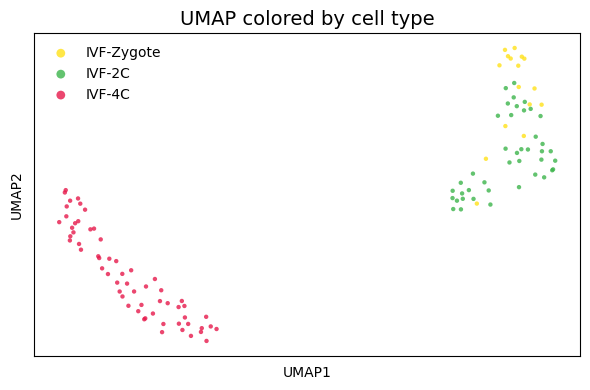

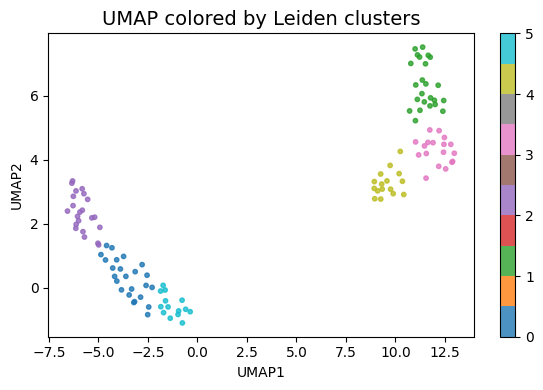

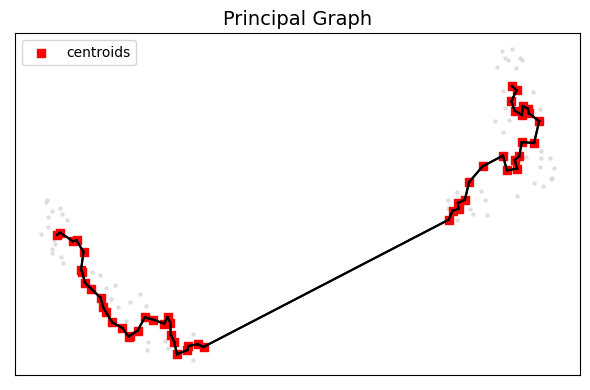

由于没有分支点，跳过 Cell States 图的绘制。


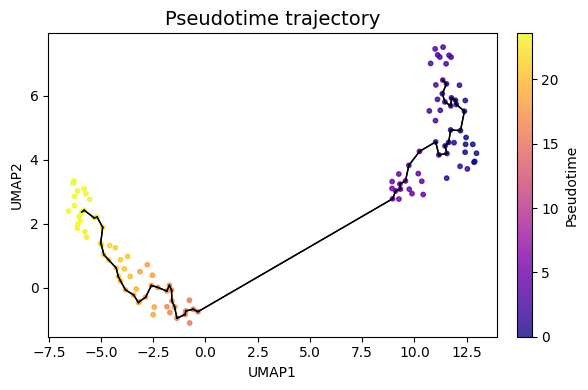

In [20]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
from scipy.sparse import csr_matrix
from py_monocle import learn_graph, order_cells, compute_cell_states
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ==================== 1. 读取表达量矩阵 ====================
# 假设文件是 tab 分隔，第一列是基因名，第一行是细胞名
df = pd.read_csv('IVF_118cells_readcounts.txt', sep='\t', index_col=0)
# df 的形状: (n_genes, n_cells)

# 转置为 AnnData 标准格式: cells × genes
adata = ad.AnnData(df.T)
print(f"原始数据: {adata.n_obs} 细胞, {adata.n_vars} 基因")

# ==================== 2. 基本预处理 ====================
# 过滤：在少于3个细胞中表达的基因、总counts过低的细胞（根据实际情况调整）
sc.pp.filter_cells(adata, min_genes=200)   # 每个细胞至少表达200个基因
sc.pp.filter_genes(adata, min_cells=3)     # 每个基因至少在3个细胞中表达

# 标准化：总counts归一化到1e4，然后log1p转换
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# 识别高变基因（用于下游降维）
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor='seurat_v3', batch_key=None)
adata.raw = adata  # 保存原始标准化数据
adata = adata[:, adata.var.highly_variable]

# ==================== 3. 降维（PCA + UMAP） ====================
sc.tl.pca(adata, n_comps=50, svd_solver='auto')
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)  # 用于UMAP和聚类
sc.tl.umap(adata, min_dist=0.3, spread=1.0)

# 提取UMAP坐标（用于py_monocle）
umap_coords = adata.obsm['X_umap']  # shape (n_cells, 2)

# ==================== 4. 聚类（Leiden） ====================
sc.tl.leiden(adata, resolution=0.8)  # 提高分辨率可能产生更多分支
clusters = adata.obs['leiden'].astype(int).values  # 从0开始的整数标签

# ==================== 5. 拟时序分析（py_monocle） ====================
# 注意：py_monocle的learn_graph需要二维坐标（UMAP）和聚类标签
projected_points, mst, centroids = learn_graph(
    matrix=umap_coords,
    clusters=clusters
)

# 将mst稀疏矩阵转换为边列表 (n_edges, 2)
if hasattr(mst, 'tocoo'):
    coo = mst.tocoo()
    edges = np.vstack((coo.row, coo.col)).T
else:
    edges = mst  # 假设已经是边列表

# 尝试计算细胞状态（如果无分支点则跳过）
try:
    cell_states = compute_cell_states(projected_points, centroids, mst)
    has_branch = True
except IndexError:
    print("警告：最小生成树中没有分支节点（所有节点度数≤2），无法计算细胞状态。将设置 cell_states 为全零。")
    cell_states = np.zeros(umap_coords.shape[0])
    has_branch = False

# 确定根细胞：选择聚类中最早期的细胞（例如根据生物学知识）
# 如果没有先验知识，可以选一个UMAP坐标最边缘的细胞或特定cluster
# 这里演示：选择UMAP第一维最小的细胞作为根
#root_cell_idx = np.argmin(umap_coords[:, 0])

# 选择 UMAP 第一维最大的细胞作为根（反转方向）
root_cell_idx = np.argmax(umap_coords[:, 0])

# 推断拟时序
pseudotime = order_cells(
    umap_coords,
    centroids,
    mst=mst,
    projected_points=projected_points,
    root_cells=root_cell_idx,
)

# 将拟时序值添加到AnnData对象中便于后续分析
adata.obs['pseudotime'] = pseudotime

# ==================== 6. 结果可视化 ====================
# 设置绘图风格
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'

# ==================== 读取细胞类型元数据 ====================
meta_df = pd.read_csv('IVF_118cells_cell_metadata.txt', sep='\t', index_col=0)  # 以id为索引
# 确保索引名称与 adata.obs_names 对应
adata.obs['cell_type'] = meta_df.loc[adata.obs_names, 'cell_type']

# 定义颜色映射
cell_type_colors = {
    "IVF-Zygote": "#ffe119",
    "IVF-2C": "#3cb44b",
    "IVF-4C": "#e6194b"
}
# 为每个细胞分配颜色
adata.obs['cell_type_color'] = adata.obs['cell_type'].map(cell_type_colors)

# ==================== 绘制 UMAP 按 cell_type 着色 ====================
fig, ax = plt.subplots(figsize=(6,4))
# 按细胞类型分别画点，以便添加图例
for ct, color in cell_type_colors.items():
    mask = adata.obs['cell_type'] == ct
    ax.scatter(umap_coords[mask, 0], umap_coords[mask, 1], 
               c=color, s=10, alpha=0.8, label=ct, edgecolors='none', rasterized=True)
ax.set_title("UMAP colored by cell type", fontsize=14)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(markerscale=2, fontsize=10, frameon=False)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig('IVF_scRNAseq_UMAP_cell_type.svg', dpi=300, bbox_inches='tight')
plt.show()

# --- 图1: UMAP着色聚类 ---
fig, ax = plt.subplots(figsize=(6,4))
scatter = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=clusters, cmap='tab10', s=10, alpha=0.8)
ax.set_title("UMAP colored by Leiden clusters", fontsize=14)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
plt.colorbar(scatter)
plt.tight_layout()
plt.savefig('IVF_scRNAseq_UMAP_clusters.svg', dpi=300, bbox_inches='tight')
plt.show()

# --- 图2: Principal Graph ---
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(umap_coords[:,0], umap_coords[:,1], c='lightgray', s=5, alpha=0.6, rasterized=True)
# 画最小生成树边（注意edges是整数索引，对应centroids的行）
for edge in edges:
    ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1.5)
ax.scatter(centroids[:,0], centroids[:,1], c='red', s=30, marker='s', label='centroids')
ax.set_title("Principal Graph", fontsize=14)
ax.set_xticks([]); ax.set_yticks([])
ax.legend()
plt.tight_layout()
plt.savefig('IVF_scRNAseq_Principal_Graph.svg', dpi=300, bbox_inches='tight')
plt.show()

# --- 图3: Cell States（仅当有分支时有效） ---
if has_branch:
    fig, ax = plt.subplots(figsize=(6,4))
    sc = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=cell_states, cmap='nipy_spectral', s=10, alpha=0.8, rasterized=True)
    for edge in edges:
        ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1)
    ax.set_title("Cell States", fontsize=14)
    ax.set_xticks([]); ax.set_yticks([])
    cbar = plt.colorbar(sc, fraction=0.046, pad=0.04)
    cbar.set_label('State', fontsize=10)
    plt.tight_layout()
    plt.savefig('IVF_scRNAseq_Cell_States.svg', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("由于没有分支点，跳过 Cell States 图的绘制。")

# --- 图4: Pseudotime ---
fig, ax = plt.subplots(figsize=(6,4))
sc = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=pseudotime, cmap='plasma', s=10, alpha=0.8, rasterized=True)
for edge in edges:
    ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1)
ax.set_title("Pseudotime trajectory", fontsize=14)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
cbar = plt.colorbar(sc, fraction=0.046, pad=0.04)
cbar.set_label('Pseudotime', fontsize=10)
plt.tight_layout()
plt.savefig('IVF_scRNAseq_pseudotime_results.svg', dpi=300, bbox_inches='tight')
plt.show()

# 可选：保存拟时序结果
results_df = pd.DataFrame({
    'cell_id': adata.obs_names,
    'pseudotime': pseudotime,
    'cluster': clusters,
    'cell_state': cell_states if has_branch else np.nan
})
results_df.to_csv('IVF_scRNAseq_pseudotime_results.txt', sep='\t', index=False)

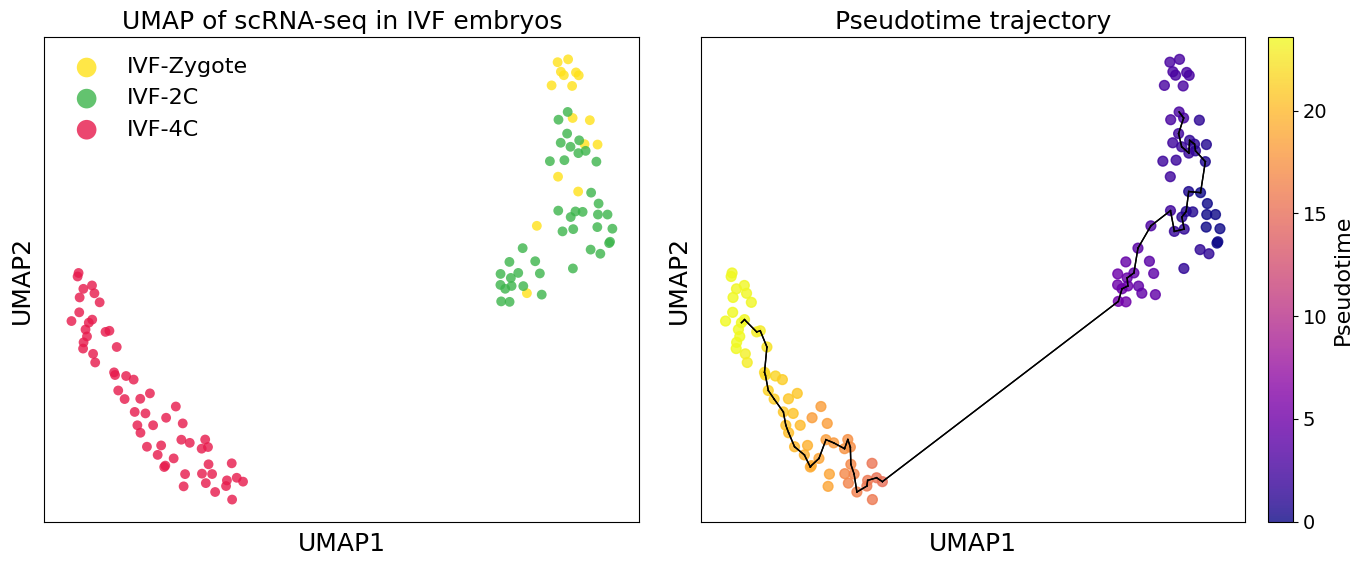

In [29]:
# ==================== 6. 结果可视化（合并为左右子图，字体整体放大） ====================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ---------- 全局字体放大 ----------
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
plt.rcParams['font.size'] = 18          # 基础字体大小（影响标题、标签、图例等）
plt.rcParams['axes.labelsize'] = 18     # 轴标签字体大小
plt.rcParams['xtick.labelsize'] = 16    # 刻度标签字体（可略小）
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.fontsize'] = 16    # 图例字体
# 注意：没有 colorbar.label.size 这个 rcParam，所以删掉

# ---------- 读取细胞类型元数据（如果之前未读取） ----------
meta_df = pd.read_csv('IVF_118cells_cell_metadata.txt', sep='\t', index_col=0)
adata.obs['cell_type'] = meta_df.loc[adata.obs_names, 'cell_type']

cell_type_colors = {
    "IVF-Zygote": "#ffe119",
    "IVF-2C": "#3cb44b",
    "IVF-4C": "#e6194b"
}
adata.obs['cell_type_color'] = adata.obs['cell_type'].map(cell_type_colors)

# ---------- 创建 1行2列子图，适当增大画布 ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ---------- 左子图：UMAP 按细胞类型着色 ----------
for ct, color in cell_type_colors.items():
    mask = adata.obs['cell_type'] == ct
    ax1.scatter(umap_coords[mask, 0], umap_coords[mask, 1],
                c=color, s=50, alpha=0.8, label=ct, edgecolors='none', rasterized=True)
ax1.set_title("UMAP of scRNA-seq in IVF embryos", fontsize=18)  # 标题稍大
ax1.set_xlabel("UMAP1")
ax1.set_ylabel("UMAP2")
ax1.legend(markerscale=2, frameon=False)
ax1.set_xticks([])
ax1.set_yticks([])

# ---------- 右子图：Pseudotime 轨迹 ----------
sc = ax2.scatter(umap_coords[:, 0], umap_coords[:, 1],
                 c=pseudotime, cmap='plasma', s=50, alpha=0.8, rasterized=True)
# 绘制最小生成树边
for edge in edges:
    ax2.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1)
ax2.set_title("Pseudotime trajectory", fontsize=18)
ax2.set_xlabel("UMAP1")
ax2.set_ylabel("UMAP2")
ax2.set_xticks([])
ax2.set_yticks([])

# 添加颜色条并单独设置字体
cbar = fig.colorbar(sc, ax=ax2, fraction=0.046, pad=0.04)
cbar.set_label('Pseudotime', fontsize=16)   # 颜色条标签字体
cbar.ax.tick_params(labelsize=14)           # 颜色条刻度字体

# ---------- 调整布局并保存 ----------
plt.tight_layout()
plt.savefig('IVF_scRNAseq_UMAP_celltype_pseudotime_combined.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

2C-iDEG1: 27 个细胞
2C-iDEG2: 15 个细胞
4C-iDEG1: 15 个细胞
4C-iDEG2: 45 个细胞
成功分配亚群的细胞数: 102

各亚群细胞数量：
  2C-iDEG1: 27 个细胞
  2C-iDEG2: 15 个细胞
  4C-iDEG1: 15 个细胞
  4C-iDEG2: 45 个细胞


/home/lihaoxing/tmp/ipykernel_114975/2860008899.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

2C-iDEG1 vs. 2C-iDEG2: Mann-Whitney-Wilcoxon test two-sided, P_val:5.298e-04 U_stat=7.050e+01
4C-iDEG1 vs. 4C-iDEG2: Mann-Whitney-Wilcoxon test two-sided, P_val:8.304e-09 U_stat=6.750e+02


/home/lihaoxing/tmp/ipykernel_114975/2860008899.py:145: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['iDEG1', 'iDEG2', 'iDEG1', 'iDEG2'], fontsize=16)


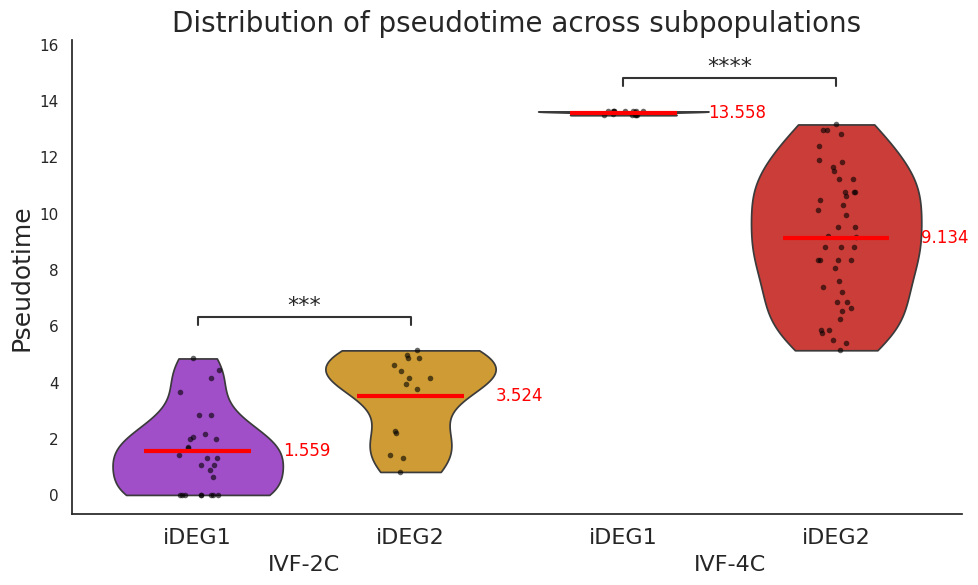

In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")  # 去掉网格

# =========================
# 1. 读取伪时间数据
# =========================
pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
pseudo_df.columns = ['cell_id', 'pseudotime']

# =========================
# 2. 读取四个亚群 ID
# =========================
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_files = {
    '2C-iDEG1': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG1.txt",
    '2C-iDEG2': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-2C-iDEG2.txt",
    '4C-iDEG1': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG1.txt",
    '4C-iDEG2': "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF-4C-iDEG2.txt"
}

subgroup_cells = {}
for name, fpath in subgroup_files.items():
    cells = read_ids(fpath)
    subgroup_cells[name] = cells
    print(f"{name}: {len(cells)} 个细胞")

# =========================
# 3. 为细胞分配亚群标签
# =========================
cell_to_group = {}
for group, cells in subgroup_cells.items():
    for cell in cells:
        cell_to_group[cell] = group

pseudo_df['subgroup'] = pseudo_df['cell_id'].map(cell_to_group)
pseudo_df = pseudo_df.dropna(subset=['subgroup'])
print(f"成功分配亚群的细胞数: {len(pseudo_df)}")

# =========================
# 4. 定义顺序和颜色
# =========================
ordered = ['2C-iDEG1', '2C-iDEG2', '4C-iDEG1', '4C-iDEG2']
color_mapping = {
    '2C-iDEG1': '#A73BDD',
    '2C-iDEG2': '#E7A31B',
    '4C-iDEG1': '#2292A4',
    '4C-iDEG2': '#E22720'
}

# 打印各亚群细胞数量
print("\n各亚群细胞数量：")
for g in ordered:
    cnt = pseudo_df[pseudo_df['subgroup'] == g].shape[0]
    print(f"  {g}: {cnt} 个细胞")

# =========================
# 5. 绘图
# =========================
fig, ax = plt.subplots(figsize=(10, 6))

# ---- 小提琴 (无内部 box) ----
sns.violinplot(
    x='subgroup',
    y='pseudotime',
    data=pseudo_df,
    order=ordered,
    palette=color_mapping,
    inner=None,
    cut=0,
    ax=ax
)

# ---- 散点 (黑色半透明) ----
sns.stripplot(
    x='subgroup',
    y='pseudotime',
    data=pseudo_df,
    order=ordered,
    color='black',
    size=4,
    alpha=0.6,
    jitter=True,
    ax=ax
)

# ---- 均值红色线段 + 数值 ----
group_means = pseudo_df.groupby('subgroup')['pseudotime'].mean()
for i, g in enumerate(ordered):
    mean_val = group_means[g]
    ax.hlines(
        y=mean_val,
        xmin=i - 0.25,
        xmax=i + 0.25,
        color='red',
        linewidth=3,
        zorder=5
    )
    ax.text(
        i + 0.4,
        mean_val,
        f"{mean_val:.3f}",
        ha='left',
        va='center',
        fontsize=12,
        color='red'
    )

# ---- 显著性标注 (Mann-Whitney) ----
pairs = [
    ('2C-iDEG1', '2C-iDEG2'),
    ('4C-iDEG1', '4C-iDEG2')
]
annotator = Annotator(
    ax,
    pairs,
    data=pseudo_df,
    x='subgroup',
    y='pseudotime',
    order=ordered
)
annotator.configure(
    test='Mann-Whitney',
    text_format='star',
    loc='inside',
    fontsize=16
)
annotator.apply_and_annotate()

# ---- x 轴标签简化 ----
ax.set_xticklabels(['iDEG1', 'iDEG2', 'iDEG1', 'iDEG2'], fontsize=16)
ax.text(0.5, -0.12, 'IVF-2C', transform=ax.get_xaxis_transform(), ha='center', fontsize=16)
ax.text(2.5, -0.12, 'IVF-4C', transform=ax.get_xaxis_transform(), ha='center', fontsize=16)

# ---- 轴标签和标题 ----
ax.set_ylabel('Pseudotime', fontsize=18)
ax.set_xlabel('')
ax.set_title('Distribution of pseudotime across subpopulations', fontsize=20)

sns.despine()
ax.grid(False)
plt.tight_layout()
plt.savefig('Subgroup_pseudotime_violinplot_optimized.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

原始数据: 80 细胞, 20289 基因


/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:72: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  warnings.warn(
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/scanpy/preprocessing/_pca.py:314: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm["X_pca"] = X_pca


警告：最小生成树中没有分支节点（所有节点度数≤2），无法计算细胞状态。将设置 cell_states 为全零。


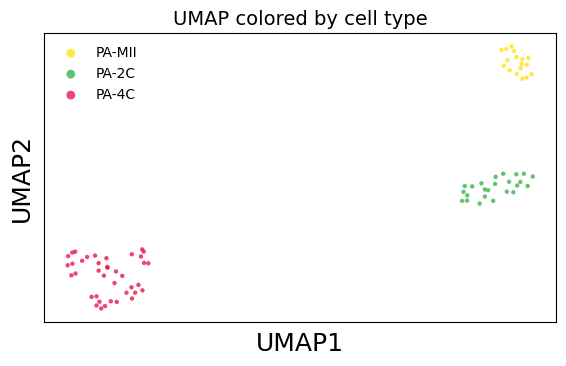

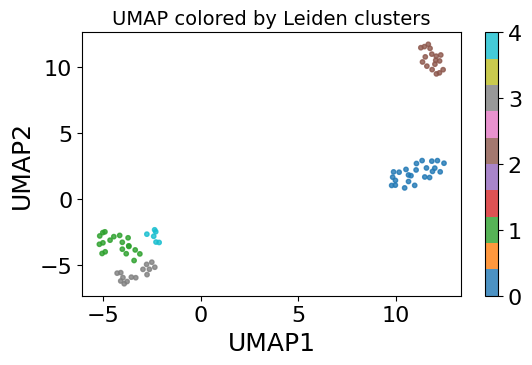

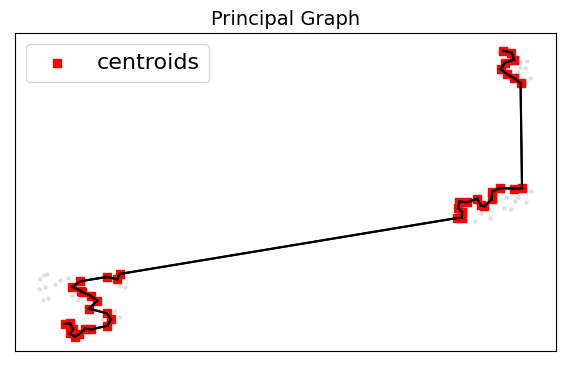

由于没有分支点，跳过 Cell States 图的绘制。


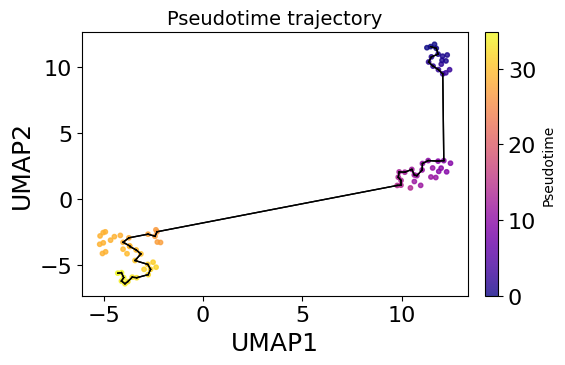

In [30]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
from scipy.sparse import csr_matrix
from py_monocle import learn_graph, order_cells, compute_cell_states
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ==================== 1. 读取表达量矩阵 ====================
# 假设文件是 tab 分隔，第一列是基因名，第一行是细胞名
df = pd.read_csv('PA_80cells_readcounts.txt', sep='\t', index_col=0)
# df 的形状: (n_genes, n_cells)

# 转置为 AnnData 标准格式: cells × genes
adata = ad.AnnData(df.T)
print(f"原始数据: {adata.n_obs} 细胞, {adata.n_vars} 基因")

# ==================== 2. 基本预处理 ====================
# 过滤：在少于3个细胞中表达的基因、总counts过低的细胞（根据实际情况调整）
sc.pp.filter_cells(adata, min_genes=200)   # 每个细胞至少表达200个基因
sc.pp.filter_genes(adata, min_cells=3)     # 每个基因至少在3个细胞中表达

# 标准化：总counts归一化到1e4，然后log1p转换
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# 识别高变基因（用于下游降维）
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor='seurat_v3', batch_key=None)
adata.raw = adata  # 保存原始标准化数据
adata = adata[:, adata.var.highly_variable]

# ==================== 3. 降维（PCA + UMAP） ====================
sc.tl.pca(adata, n_comps=10, svd_solver='auto')
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=10)  # 用于UMAP和聚类
sc.tl.umap(adata, min_dist=0.3, spread=1.0)

# 提取UMAP坐标（用于py_monocle）
umap_coords = adata.obsm['X_umap']  # shape (n_cells, 2)

# ==================== 4. 聚类（Leiden） ====================
sc.tl.leiden(adata, resolution=0.8)  # 提高分辨率可能产生更多分支
clusters = adata.obs['leiden'].astype(int).values  # 从0开始的整数标签

# ==================== 5. 拟时序分析（py_monocle） ====================
# 注意：py_monocle的learn_graph需要二维坐标（UMAP）和聚类标签
projected_points, mst, centroids = learn_graph(
    matrix=umap_coords,
    clusters=clusters
)

# 将mst稀疏矩阵转换为边列表 (n_edges, 2)
if hasattr(mst, 'tocoo'):
    coo = mst.tocoo()
    edges = np.vstack((coo.row, coo.col)).T
else:
    edges = mst  # 假设已经是边列表

# 尝试计算细胞状态（如果无分支点则跳过）
try:
    cell_states = compute_cell_states(projected_points, centroids, mst)
    has_branch = True
except IndexError:
    print("警告：最小生成树中没有分支节点（所有节点度数≤2），无法计算细胞状态。将设置 cell_states 为全零。")
    cell_states = np.zeros(umap_coords.shape[0])
    has_branch = False

# 确定根细胞：选择聚类中最早期的细胞（例如根据生物学知识）
# 如果没有先验知识，可以选一个UMAP坐标最边缘的细胞或特定cluster
# 这里演示：选择UMAP第一维最小的细胞作为根
#root_cell_idx = np.argmin(umap_coords[:, 0])

# 选择 UMAP 第一维最大的细胞作为根（反转方向）
#root_cell_idx = np.argmax(umap_coords[:, 0])
# 选择 UMAP 第一维+第二维最大的细胞作为根（最右上角）
root_cell_idx = np.argmax(umap_coords[:, 0] + umap_coords[:, 1])

# 推断拟时序
pseudotime = order_cells(
    umap_coords,
    centroids,
    mst=mst,
    projected_points=projected_points,
    root_cells=root_cell_idx,
)

# 将拟时序值添加到AnnData对象中便于后续分析
adata.obs['pseudotime'] = pseudotime

# ==================== 6. 结果可视化 ====================
# 设置绘图风格
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'

# ==================== 读取细胞类型元数据 ====================
meta_df = pd.read_csv('PA_80cells_cell_metadata.txt', sep='\t', index_col=0)  # 以id为索引
# 确保索引名称与 adata.obs_names 对应
adata.obs['cell_type'] = meta_df.loc[adata.obs_names, 'cell_type']

# 定义颜色映射
cell_type_colors = {
    "PA-MII": "#ffe119",
    "PA-2C": "#3cb44b",
    "PA-4C": "#e6194b"
}
# 为每个细胞分配颜色
adata.obs['cell_type_color'] = adata.obs['cell_type'].map(cell_type_colors)

# ==================== 绘制 UMAP 按 cell_type 着色 ====================
fig, ax = plt.subplots(figsize=(6,4))
# 按细胞类型分别画点，以便添加图例
for ct, color in cell_type_colors.items():
    mask = adata.obs['cell_type'] == ct
    ax.scatter(umap_coords[mask, 0], umap_coords[mask, 1], 
               c=color, s=10, alpha=0.8, label=ct, edgecolors='none', rasterized=True)
ax.set_title("UMAP colored by cell type", fontsize=14)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(markerscale=2, fontsize=10, frameon=False)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig('PA_scRNAseq_UMAP_cell_type.svg', dpi=300, bbox_inches='tight')
plt.show()

# --- 图1: UMAP着色聚类 ---
fig, ax = plt.subplots(figsize=(6,4))
scatter = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=clusters, cmap='tab10', s=10, alpha=0.8)
ax.set_title("UMAP colored by Leiden clusters", fontsize=14)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
plt.colorbar(scatter)
plt.tight_layout()
plt.savefig('PA_scRNAseq_UMAP_clusters.svg', dpi=300, bbox_inches='tight')
plt.show()

# --- 图2: Principal Graph ---
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(umap_coords[:,0], umap_coords[:,1], c='lightgray', s=5, alpha=0.6, rasterized=True)
# 画最小生成树边（注意edges是整数索引，对应centroids的行）
for edge in edges:
    ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1.5)
ax.scatter(centroids[:,0], centroids[:,1], c='red', s=30, marker='s', label='centroids')
ax.set_title("Principal Graph", fontsize=14)
ax.set_xticks([]); ax.set_yticks([])
ax.legend()
plt.tight_layout()
plt.savefig('PA_scRNAseq_Principal_Graph.svg', dpi=300, bbox_inches='tight')
plt.show()

# --- 图3: Cell States（仅当有分支时有效） ---
if has_branch:
    fig, ax = plt.subplots(figsize=(6,4))
    sc = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=cell_states, cmap='nipy_spectral', s=10, alpha=0.8, rasterized=True)
    for edge in edges:
        ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1)
    ax.set_title("Cell States", fontsize=14)
    ax.set_xticks([]); ax.set_yticks([])
    cbar = plt.colorbar(sc, fraction=0.046, pad=0.04)
    cbar.set_label('State', fontsize=10)
    plt.tight_layout()
    plt.savefig('PA_scRNAseq_Cell_States.svg', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("由于没有分支点，跳过 Cell States 图的绘制。")

# --- 图4: Pseudotime ---
fig, ax = plt.subplots(figsize=(6,4))
sc = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=pseudotime, cmap='plasma', s=10, alpha=0.8, rasterized=True)
for edge in edges:
    ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1)
ax.set_title("Pseudotime trajectory", fontsize=14)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
cbar = plt.colorbar(sc, fraction=0.046, pad=0.04)
cbar.set_label('Pseudotime', fontsize=10)
plt.tight_layout()
plt.savefig('PA_scRNAseq_pseudotime_results.svg', dpi=300, bbox_inches='tight')
plt.show()

# 可选：保存拟时序结果
results_df = pd.DataFrame({
    'cell_id': adata.obs_names,
    'pseudotime': pseudotime,
    'cluster': clusters,
    'cell_state': cell_states if has_branch else np.nan
})
results_df.to_csv('PA_scRNAseq_pseudotime_results.txt', sep='\t', index=False)

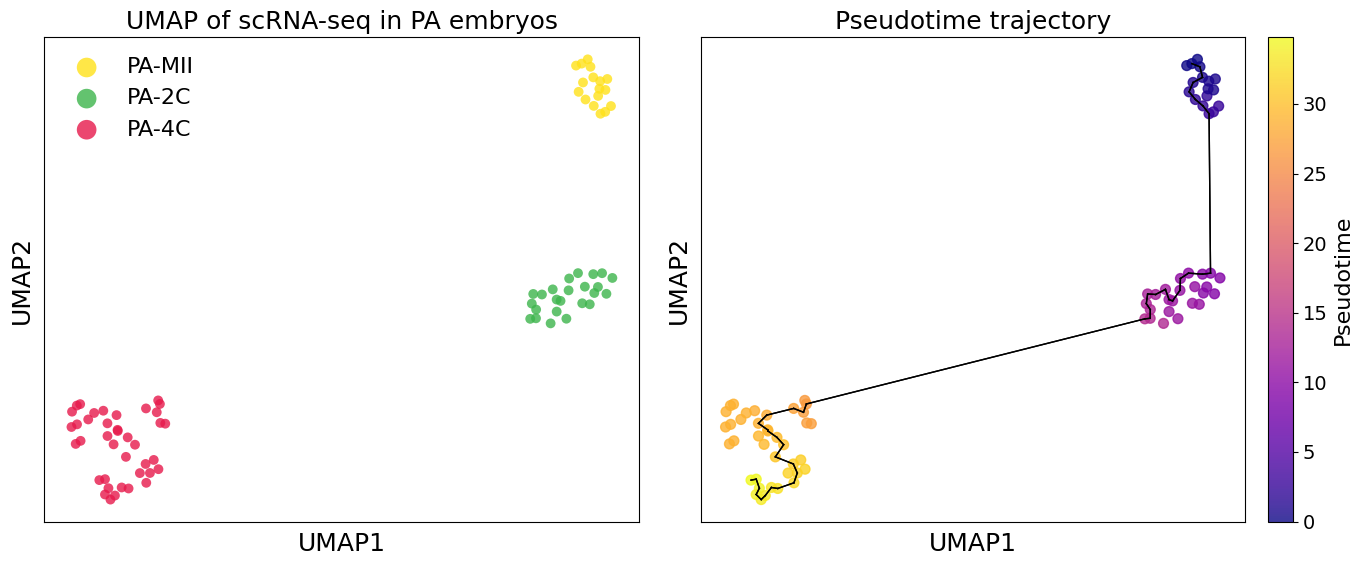

In [31]:
# ==================== 6. 结果可视化（合并为左右子图，字体整体放大） ====================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ---------- 全局字体放大 ----------
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
plt.rcParams['font.size'] = 18          # 基础字体大小
plt.rcParams['axes.labelsize'] = 18     # 轴标签字体
plt.rcParams['xtick.labelsize'] = 16    # 刻度标签
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.fontsize'] = 16    # 图例字体
# 注意：不使用无效的 'colorbar.label.size' 键

# ---------- 读取细胞类型元数据（如果之前未读取） ----------
meta_df = pd.read_csv('PA_80cells_cell_metadata.txt', sep='\t', index_col=0)
adata.obs['cell_type'] = meta_df.loc[adata.obs_names, 'cell_type']

cell_type_colors = {
    "PA-MII": "#ffe119",
    "PA-2C": "#3cb44b",
    "PA-4C": "#e6194b"
}
adata.obs['cell_type_color'] = adata.obs['cell_type'].map(cell_type_colors)

# ---------- 创建 1行2列子图，画布适当增大 ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ---------- 左子图：UMAP 按细胞类型着色 ----------
for ct, color in cell_type_colors.items():
    mask = adata.obs['cell_type'] == ct
    ax1.scatter(umap_coords[mask, 0], umap_coords[mask, 1],
                c=color, s=50, alpha=0.8, label=ct, edgecolors='none', rasterized=True)
ax1.set_title("UMAP of scRNA-seq in PA embryos", fontsize=18)  # 可自定义标题
ax1.set_xlabel("UMAP1")
ax1.set_ylabel("UMAP2")
ax1.legend(markerscale=2, frameon=False)
ax1.set_xticks([])
ax1.set_yticks([])

# ---------- 右子图：Pseudotime 轨迹 ----------
sc = ax2.scatter(umap_coords[:, 0], umap_coords[:, 1],
                 c=pseudotime, cmap='plasma', s=50, alpha=0.8, rasterized=True)
# 绘制最小生成树边
for edge in edges:
    ax2.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1)
ax2.set_title("Pseudotime trajectory", fontsize=18)
ax2.set_xlabel("UMAP1")
ax2.set_ylabel("UMAP2")
ax2.set_xticks([])
ax2.set_yticks([])

# 添加颜色条并设置字体
cbar = fig.colorbar(sc, ax=ax2, fraction=0.046, pad=0.04)
cbar.set_label('Pseudotime', fontsize=16)
cbar.ax.tick_params(labelsize=14)

# ---------- 调整布局并保存 ----------
plt.tight_layout()
plt.savefig('PA_scRNAseq_UMAP_celltype_pseudotime_combined.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

2C-iDEG1: 18 个细胞
2C-iDEG2: 6 个细胞
4C-iDEG1: 23 个细胞
4C-iDEG2: 16 个细胞
成功分配亚群的细胞数: 60

各亚群细胞数量：
  2C-iDEG1: 15 个细胞
  2C-iDEG2: 6 个细胞
  4C-iDEG1: 23 个细胞
  4C-iDEG2: 16 个细胞


/home/lihaoxing/tmp/ipykernel_114975/368515420.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

2C-iDEG1 vs. 2C-iDEG2: Mann-Whitney-Wilcoxon test two-sided, P_val:2.747e-01 U_stat=3.050e+01
4C-iDEG1 vs. 4C-iDEG2: Mann-Whitney-Wilcoxon test two-sided, P_val:9.713e-04 U_stat=2.995e+02


/home/lihaoxing/tmp/ipykernel_114975/368515420.py:145: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['iDEG1', 'iDEG2', 'iDEG1', 'iDEG2'], fontsize=16)


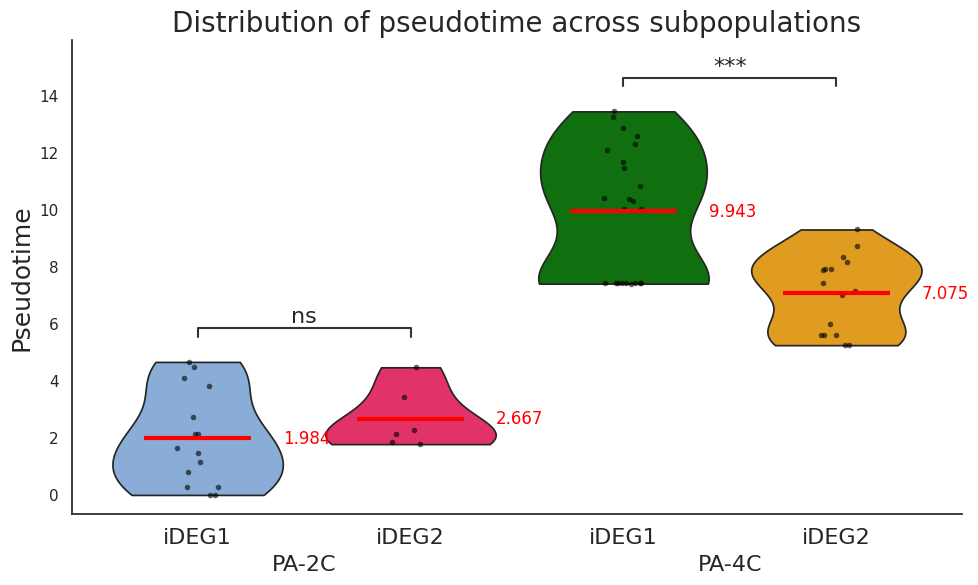

In [35]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")  # 去掉网格

# =========================
# 1. 读取伪时间数据
# =========================
pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
pseudo_df.columns = ['cell_id', 'pseudotime']

# =========================
# 2. 读取四个亚群 ID
# =========================
def read_ids(filepath):
    with open(filepath) as f:
        return [line.strip() for line in f if line.strip()]

subgroup_files = {
    '2C-iDEG1': "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA-2C-iDEG1.txt",
    '2C-iDEG2': "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA-2C-iDEG2.txt",
    '4C-iDEG1': "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA-4C-iDEG1.txt",
    '4C-iDEG2': "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA-4C-iDEG2.txt"
}

subgroup_cells = {}
for name, fpath in subgroup_files.items():
    cells = read_ids(fpath)
    subgroup_cells[name] = cells
    print(f"{name}: {len(cells)} 个细胞")

# =========================
# 3. 为细胞分配亚群标签
# =========================
cell_to_group = {}
for group, cells in subgroup_cells.items():
    for cell in cells:
        cell_to_group[cell] = group

pseudo_df['subgroup'] = pseudo_df['cell_id'].map(cell_to_group)
pseudo_df = pseudo_df.dropna(subset=['subgroup'])
print(f"成功分配亚群的细胞数: {len(pseudo_df)}")

# =========================
# 4. 定义顺序和颜色
# =========================
ordered = ['2C-iDEG1', '2C-iDEG2', '4C-iDEG1', '4C-iDEG2']
color_mapping = {
    '2C-iDEG1': '#7dace4',
    '2C-iDEG2': '#ff165d',
    '4C-iDEG1': 'green',
    '4C-iDEG2': 'orange'
}

# 打印各亚群细胞数量
print("\n各亚群细胞数量：")
for g in ordered:
    cnt = pseudo_df[pseudo_df['subgroup'] == g].shape[0]
    print(f"  {g}: {cnt} 个细胞")

# =========================
# 5. 绘图
# =========================
fig, ax = plt.subplots(figsize=(10, 6))

# ---- 小提琴 (无内部 box) ----
sns.violinplot(
    x='subgroup',
    y='pseudotime',
    data=pseudo_df,
    order=ordered,
    palette=color_mapping,
    inner=None,
    cut=0,
    ax=ax
)

# ---- 散点 (黑色半透明) ----
sns.stripplot(
    x='subgroup',
    y='pseudotime',
    data=pseudo_df,
    order=ordered,
    color='black',
    size=4,
    alpha=0.6,
    jitter=True,
    ax=ax
)

# ---- 均值红色线段 + 数值 ----
group_means = pseudo_df.groupby('subgroup')['pseudotime'].mean()
for i, g in enumerate(ordered):
    mean_val = group_means[g]
    ax.hlines(
        y=mean_val,
        xmin=i - 0.25,
        xmax=i + 0.25,
        color='red',
        linewidth=3,
        zorder=5
    )
    ax.text(
        i + 0.4,
        mean_val,
        f"{mean_val:.3f}",
        ha='left',
        va='center',
        fontsize=12,
        color='red'
    )

# ---- 显著性标注 (Mann-Whitney) ----
pairs = [
    ('2C-iDEG1', '2C-iDEG2'),
    ('4C-iDEG1', '4C-iDEG2')
]
annotator = Annotator(
    ax,
    pairs,
    data=pseudo_df,
    x='subgroup',
    y='pseudotime',
    order=ordered
)
annotator.configure(
    test='Mann-Whitney',
    text_format='star',
    loc='inside',
    fontsize=16
)
annotator.apply_and_annotate()

# ---- x 轴标签简化 ----
ax.set_xticklabels(['iDEG1', 'iDEG2', 'iDEG1', 'iDEG2'], fontsize=16)
ax.text(0.5, -0.12, 'PA-2C', transform=ax.get_xaxis_transform(), ha='center', fontsize=16)
ax.text(2.5, -0.12, 'PA-4C', transform=ax.get_xaxis_transform(), ha='center', fontsize=16)

# ---- 轴标签和标题 ----
ax.set_ylabel('Pseudotime', fontsize=18)
ax.set_xlabel('')
ax.set_title('Distribution of pseudotime across subpopulations', fontsize=20)

sns.despine()
ax.grid(False)
plt.tight_layout()
plt.savefig('PA_Subgroup_pseudotime_violinplot_optimized.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

原始数据: 198 细胞, 20289 基因


/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:72: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  warnings.warn(
/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/scanpy/preprocessing/_pca.py:314: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm["X_pca"] = X_pca


警告：最小生成树中没有分支节点（所有节点度数≤2），无法计算细胞状态。将设置 cell_states 为全零。


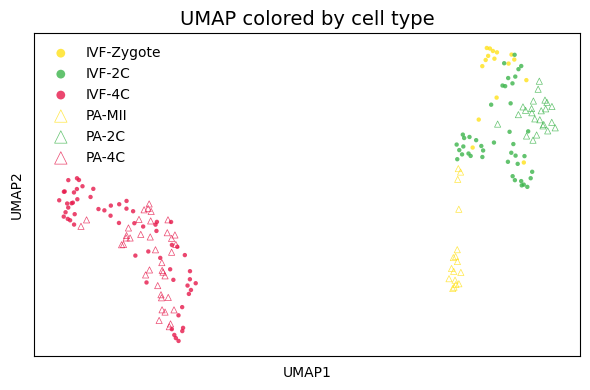

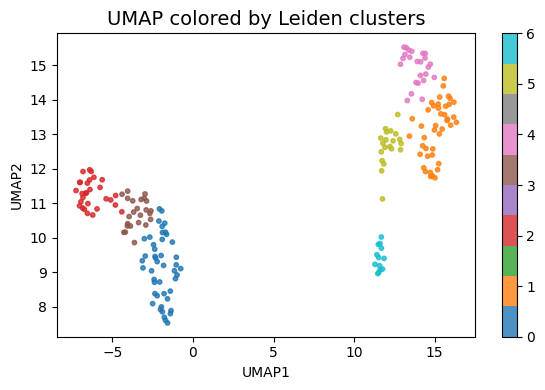

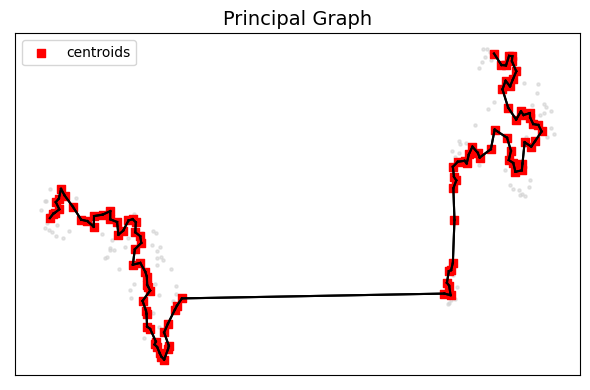

由于没有分支点，跳过 Cell States 图的绘制。


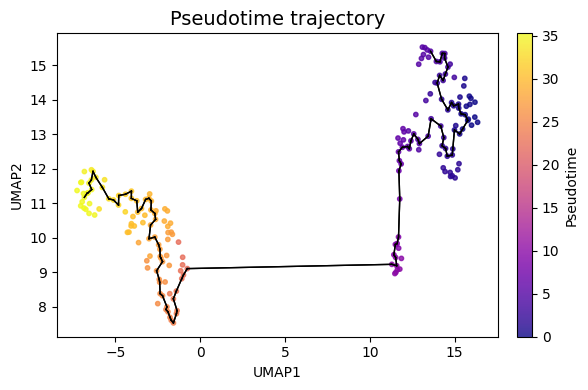

In [10]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
from scipy.sparse import csr_matrix
from py_monocle import learn_graph, order_cells, compute_cell_states
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ==================== 1. 读取表达量矩阵 ====================
# 假设文件是 tab 分隔，第一列是基因名，第一行是细胞名
df = pd.read_csv('IVF_PA_198cells_readcounts.txt', sep='\t', index_col=0)
# df 的形状: (n_genes, n_cells)

# 转置为 AnnData 标准格式: cells × genes
adata = ad.AnnData(df.T)
print(f"原始数据: {adata.n_obs} 细胞, {adata.n_vars} 基因")

# ==================== 2. 基本预处理 ====================
# 过滤：在少于3个细胞中表达的基因、总counts过低的细胞（根据实际情况调整）
sc.pp.filter_cells(adata, min_genes=200)   # 每个细胞至少表达200个基因
sc.pp.filter_genes(adata, min_cells=3)     # 每个基因至少在3个细胞中表达

# 标准化：总counts归一化到1e4，然后log1p转换
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# 识别高变基因（用于下游降维）
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor='seurat_v3', batch_key=None)
adata.raw = adata  # 保存原始标准化数据
adata = adata[:, adata.var.highly_variable]

# ==================== 3. 降维（PCA + UMAP） ====================
sc.tl.pca(adata, n_comps=50, svd_solver='auto')
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)  # 用于UMAP和聚类
sc.tl.umap(adata, min_dist=0.3, spread=1.0)

# 提取UMAP坐标（用于py_monocle）
umap_coords = adata.obsm['X_umap']  # shape (n_cells, 2)

# ==================== 4. 聚类（Leiden） ====================
sc.tl.leiden(adata, resolution=0.8)  # 提高分辨率可能产生更多分支
clusters = adata.obs['leiden'].astype(int).values  # 从0开始的整数标签

# ==================== 5. 拟时序分析（py_monocle） ====================
# 注意：py_monocle的learn_graph需要二维坐标（UMAP）和聚类标签
projected_points, mst, centroids = learn_graph(
    matrix=umap_coords,
    clusters=clusters
)

# 将mst稀疏矩阵转换为边列表 (n_edges, 2)
if hasattr(mst, 'tocoo'):
    coo = mst.tocoo()
    edges = np.vstack((coo.row, coo.col)).T
else:
    edges = mst  # 假设已经是边列表

# 尝试计算细胞状态（如果无分支点则跳过）
try:
    cell_states = compute_cell_states(projected_points, centroids, mst)
    has_branch = True
except IndexError:
    print("警告：最小生成树中没有分支节点（所有节点度数≤2），无法计算细胞状态。将设置 cell_states 为全零。")
    cell_states = np.zeros(umap_coords.shape[0])
    has_branch = False

# 确定根细胞：选择聚类中最早期的细胞（例如根据生物学知识）
# 如果没有先验知识，可以选一个UMAP坐标最边缘的细胞或特定cluster
# 这里演示：选择UMAP第一维最小的细胞作为根
#root_cell_idx = np.argmin(umap_coords[:, 0])

# 选择 UMAP 第一维最大的细胞作为根（反转方向）
root_cell_idx = np.argmax(umap_coords[:, 0])

# 推断拟时序
pseudotime = order_cells(
    umap_coords,
    centroids,
    mst=mst,
    projected_points=projected_points,
    root_cells=root_cell_idx,
)

# 将拟时序值添加到AnnData对象中便于后续分析
adata.obs['pseudotime'] = pseudotime

# ==================== 6. 结果可视化 ====================
# 设置绘图风格
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'

# ==================== 读取细胞类型元数据 ====================
meta_df = pd.read_csv('IVF_PA_198cells_cell_metadata.txt', sep='\t', index_col=0)  # 以id为索引
# 确保索引名称与 adata.obs_names 对应
adata.obs['cell_type'] = meta_df.loc[adata.obs_names, 'cell_type']

# 定义颜色映射
cell_type_colors = {
    "IVF-Zygote": "#ffe119",
    "IVF-2C": "#3cb44b",
    "IVF-4C": "#e6194b",
    "PA-MII": "#ffe119",
    "PA-2C": "#3cb44b",
    "PA-4C": "#e6194b"
}
# 为每个细胞分配颜色
adata.obs['cell_type_color'] = adata.obs['cell_type'].map(cell_type_colors)

# ==================== 绘制 UMAP 按 cell_type 着色（PA为空心三角，IVF为实心圆） ====================
fig, ax = plt.subplots(figsize=(6,4))
for ct, color in cell_type_colors.items():
    mask = adata.obs['cell_type'] == ct
    if 'PA' in ct:  # PA细胞：空心三角形
        ax.scatter(umap_coords[mask, 0], umap_coords[mask, 1],
                   marker='^', s=20, facecolors='none', edgecolors=color,
                   alpha=0.8, label=ct, linewidth=0.5, rasterized=True)
    else:           # IVF细胞：实心圆形
        ax.scatter(umap_coords[mask, 0], umap_coords[mask, 1],
                   c=color, s=10, alpha=0.8, label=ct, edgecolors='none', rasterized=True)

ax.set_title("UMAP colored by cell type", fontsize=14)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(markerscale=2, fontsize=10, frameon=False)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig('IVF_PA_scRNAseq_UMAP_cell_type.svg', dpi=300, bbox_inches='tight')
plt.show()

# --- 图1: UMAP着色聚类 ---
fig, ax = plt.subplots(figsize=(6,4))
scatter = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=clusters, cmap='tab10', s=10, alpha=0.8)
ax.set_title("UMAP colored by Leiden clusters", fontsize=14)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
plt.colorbar(scatter)
plt.tight_layout()
plt.savefig('IVF_PA_scRNAseq_UMAP_clusters.svg', dpi=300, bbox_inches='tight')
plt.show()

# --- 图2: Principal Graph ---
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(umap_coords[:,0], umap_coords[:,1], c='lightgray', s=5, alpha=0.6, rasterized=True)
# 画最小生成树边（注意edges是整数索引，对应centroids的行）
for edge in edges:
    ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1.5)
ax.scatter(centroids[:,0], centroids[:,1], c='red', s=30, marker='s', label='centroids')
ax.set_title("Principal Graph", fontsize=14)
ax.set_xticks([]); ax.set_yticks([])
ax.legend()
plt.tight_layout()
plt.savefig('IVF_PA_scRNAseq_Principal_Graph.svg', dpi=300, bbox_inches='tight')
plt.show()

# --- 图3: Cell States（仅当有分支时有效） ---
if has_branch:
    fig, ax = plt.subplots(figsize=(6,4))
    sc = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=cell_states, cmap='nipy_spectral', s=10, alpha=0.8, rasterized=True)
    for edge in edges:
        ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1)
    ax.set_title("Cell States", fontsize=14)
    ax.set_xticks([]); ax.set_yticks([])
    cbar = plt.colorbar(sc, fraction=0.046, pad=0.04)
    cbar.set_label('State', fontsize=10)
    plt.tight_layout()
    plt.savefig('IVF_PA_scRNAseq_Cell_States.svg', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("由于没有分支点，跳过 Cell States 图的绘制。")

# --- 图4: Pseudotime ---
fig, ax = plt.subplots(figsize=(6,4))
sc = ax.scatter(umap_coords[:,0], umap_coords[:,1], c=pseudotime, cmap='plasma', s=10, alpha=0.8, rasterized=True)
for edge in edges:
    ax.plot(centroids[edge, 0], centroids[edge, 1], c='black', linewidth=1)
ax.set_title("Pseudotime trajectory", fontsize=14)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
cbar = plt.colorbar(sc, fraction=0.046, pad=0.04)
cbar.set_label('Pseudotime', fontsize=10)
plt.tight_layout()
plt.savefig('IVF_PA_scRNAseq_pseudotime_results.svg', dpi=300, bbox_inches='tight')
plt.show()

# 可选：保存拟时序结果
results_df = pd.DataFrame({
    'cell_id': adata.obs_names,
    'pseudotime': pseudotime,
    'cluster': clusters,
    'cell_state': cell_states if has_branch else np.nan
})
results_df.to_csv('IVF_PA_scRNAseq_pseudotime_results.txt', sep='\t', index=False)